# House Prices

The target is a num variable, sale price in dollars. SalePrice\
Other variables:
* MSSubClass: The building class
* MSZoning: The general zoning classification
* LotFrontage: Linear feet of street connected to property
* LotArea: Lot size in square feet
* Street: Type of road access
* Alley: Type of alley access
* LotShape: General shape of property
* LandContour: Flatness of the property
* Utilities: Type of utilities available
* LotConfig: Lot configuration
* LandSlope: Slope of property
* Neighborhood: Physical locations within Ames city limits
* Condition1: Proximity to main road or railroad
* Condition2: Proximity to main road or railroad (if a second is present)
* BldgType: Type of dwelling
* HouseStyle: Style of dwelling
* OverallQual: Overall material and finish quality
* OverallCond: Overall condition rating
* YearBuilt: Original construction date
* YearRemodAdd: Remodel date
* RoofStyle: Type of roof
* RoofMatl: Roof material
* Exterior1st: Exterior covering on house
* Exterior2nd: Exterior covering on house (if more than one material)
* MasVnrType: Masonry veneer type
* MasVnrArea: Masonry veneer area in square feet
* ExterQual: Exterior material quality
* ExterCond: Present condition of the material on the exterior
* Foundation: Type of foundation
* BsmtQual: Height of the basement
* BsmtCond: General condition of the basement
* BsmtExposure: Walkout or garden level basement walls
* BsmtFinType1: Quality of basement finished area
* BsmtFinSF1: Type 1 finished square feet
* BsmtFinType2: Quality of second finished area (if present)
* BsmtFinSF2: Type 2 finished square feet
* BsmtUnfSF: Unfinished square feet of basement area
* TotalBsmtSF: Total square feet of basement area
* Heating: Type of heating
* HeatingQC: Heating quality and condition
* CentralAir: Central air conditioning
* Electrical: Electrical system
* 1stFlrSF: First Floor square feet
* 2ndFlrSF: Second floor square feet
* LowQualFinSF: Low quality finished square feet (all floors)
* GrLivArea: Above grade (ground) living area square feet
* BsmtFullBath: Basement full bathrooms
* BsmtHalfBath: Basement half bathrooms
* FullBath: Full bathrooms above grade
* HalfBath: Half baths above grade
* Bedroom: Number of bedrooms above basement level
* Kitchen: Number of kitchens
* KitchenQual: Kitchen quality
* TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)
* Functional: Home functionality rating
* Fireplaces: Number of fireplaces
* FireplaceQu: Fireplace quality
* GarageType: Garage location
* GarageYrBlt: Year garage was built
* GarageFinish: Interior finish of the garage
* GarageCars: Size of garage in car capacity
* GarageArea: Size of garage in square feet
* GarageQual: Garage quality
* GarageCond: Garage condition
* PavedDrive: Paved driveway
* WoodDeckSF: Wood deck area in square feet
* OpenPorchSF: Open porch area in square feet
* EnclosedPorch: Enclosed porch area in square feet
* 3SsnPorch: Three season porch area in square feet
* ScreenPorch: Screen porch area in square feet
* PoolArea: Pool area in square feet
* PoolQC: Pool quality
* Fence: Fence quality
* MiscFeature: Miscellaneous feature not covered in other categories
* MiscVal: $Value of miscellaneous feature
* MoSold: Month Sold
* YrSold: Year Sold
* SaleType: Type of sale
* SaleCondition: Condition of sale

## Import libraries

In [1]:
import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, QuantileTransformer, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer

from custom_transformers import on_columns
from config import config

## EDA

In [2]:
df = pd.read_csv(config.paths.dataset, index_col='Id')
df_test = pd.read_csv(config.paths.test_dataset, index_col='Id')
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.shape

(1460, 80)

In [4]:
df.columns

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

In [6]:
df.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


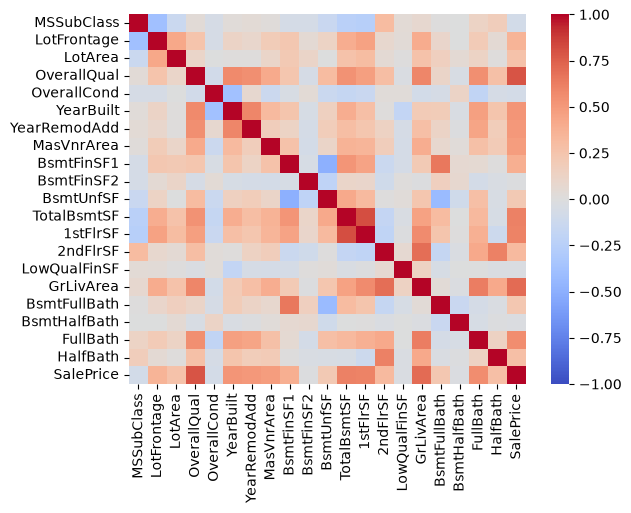

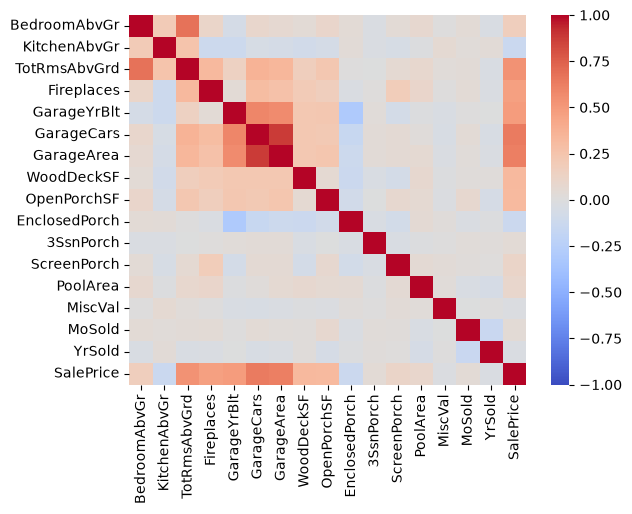

In [7]:
corr1 = df.iloc[:, :50].join(df[['SalePrice']]).corr(numeric_only=True)
sns.heatmap(corr1, vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.show()

corr2 = df.iloc[:, 50:].corr(numeric_only=True)
sns.heatmap(corr2, vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.show()

In [8]:
pd.concat([corr1.iloc[-1, :-1], corr2.iloc[-1, :-1]], axis=0).sort_values(ascending=False)

OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64

In [9]:
na = (df.isna().sum() + df_test.isna().sum()).sort_values(ascending=False)
na_nz = na[na > 0]
na_nz

PoolQC          2909.0
MiscFeature     2814.0
Alley           2721.0
Fence           2348.0
MasVnrType      1766.0
FireplaceQu     1420.0
LotFrontage      486.0
GarageFinish     159.0
GarageCond       159.0
GarageYrBlt      159.0
GarageQual       159.0
GarageType       157.0
BsmtCond          82.0
BsmtExposure      82.0
BsmtQual          81.0
BsmtFinType2      80.0
BsmtFinType1      79.0
MasVnrArea        23.0
MSZoning           4.0
BsmtFullBath       2.0
Utilities          2.0
Functional         2.0
BsmtHalfBath       2.0
TotalBsmtSF        1.0
GarageArea         1.0
GarageCars         1.0
BsmtUnfSF          1.0
Exterior2nd        1.0
BsmtFinSF1         1.0
BsmtFinSF2         1.0
KitchenQual        1.0
Exterior1st        1.0
Electrical         1.0
SaleType           1.0
dtype: float64

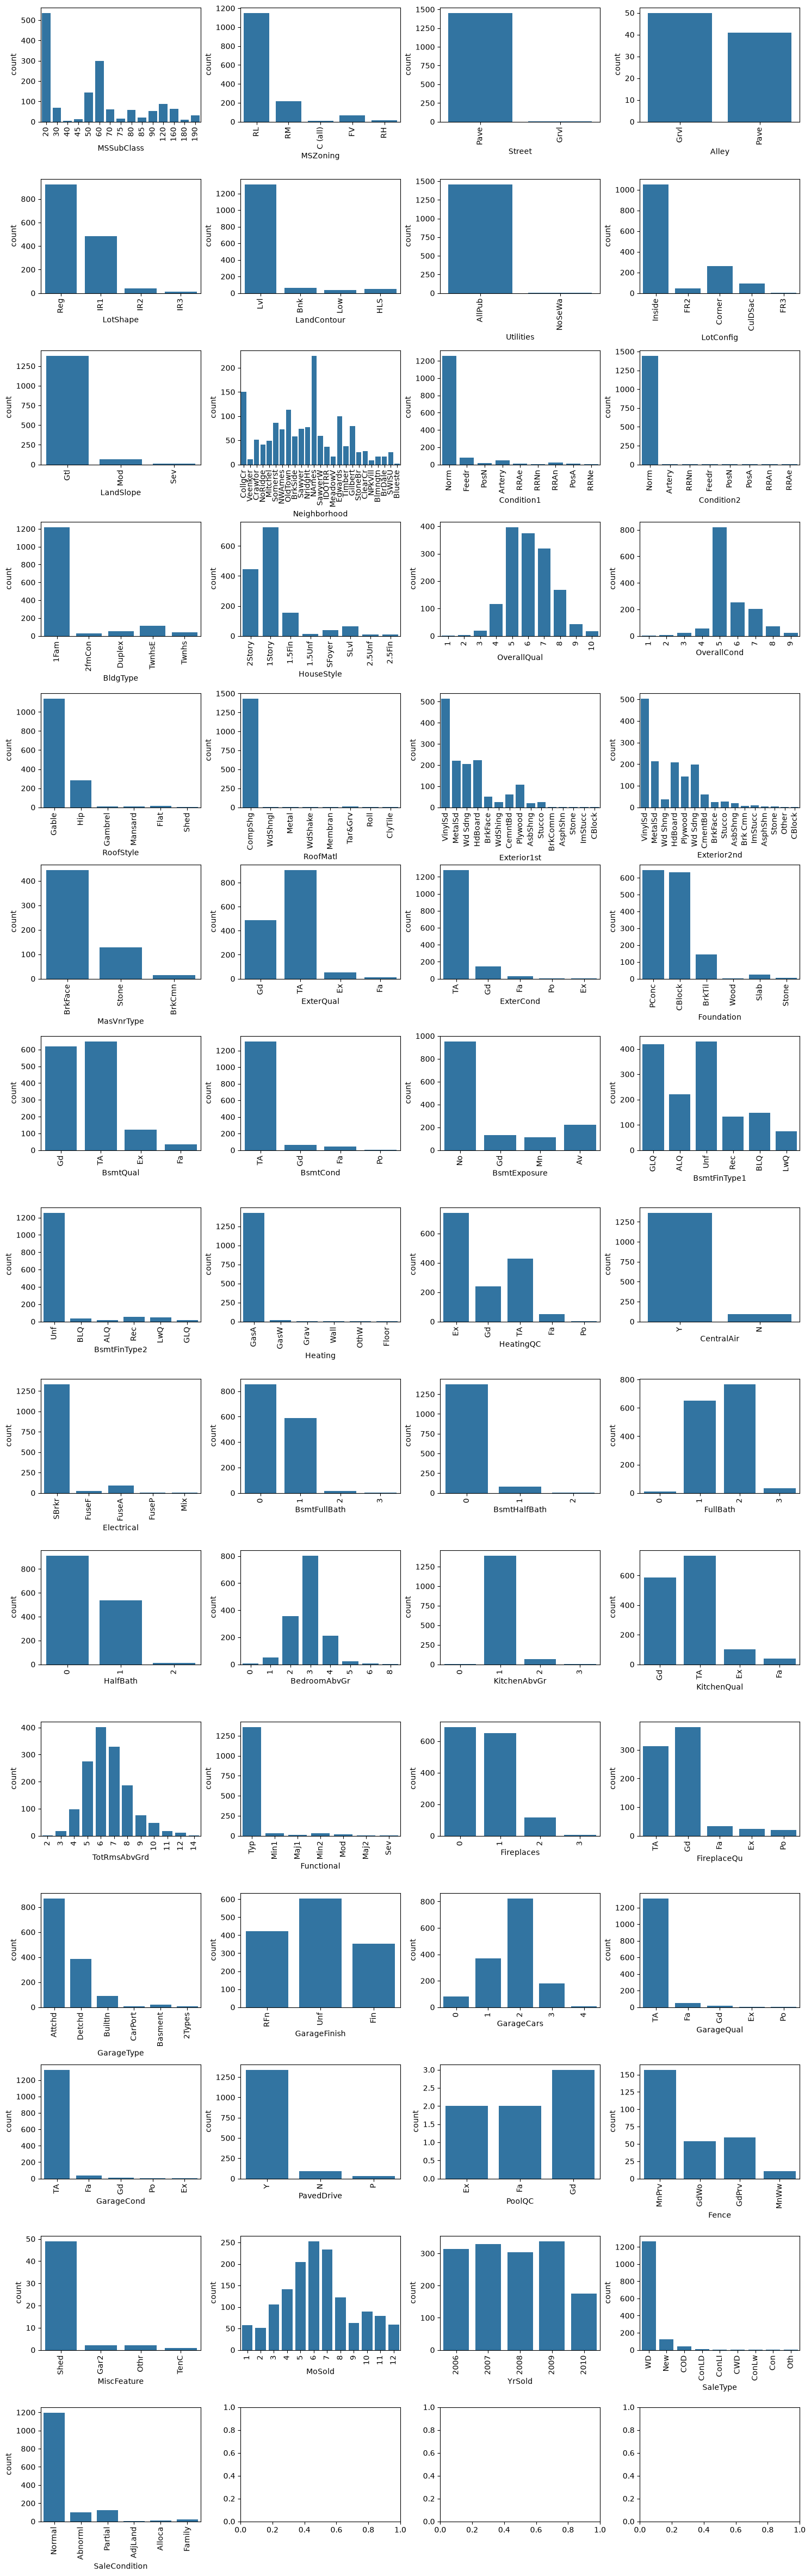

In [10]:
def plot_countplots(df: pd.DataFrame, col_names: list[str]):
    count = len(col_names)
    num_cols = 4
    num_rows = int(np.ceil(count / num_cols))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, num_rows * 4))
    for i, col_name in enumerate(col_names):
        col = i % num_cols
        row = i // num_cols
        axes[row, col].tick_params(axis='x', labelrotation=90)
        sns.countplot(df, ax=axes[row, col], x=col_name)
    fig.subplots_adjust(hspace=0.5, wspace=0.25)
    plt.show()

plot_countplots(df, [
    'MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
    'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual',
    'OverallCond', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual',
    'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
    'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageCars', 'GarageQual', 'GarageCond', 'PavedDrive', 
    'PoolQC', 'Fence', 'MiscFeature', 'MoSold', 'YrSold', 'SaleType', 'SaleCondition'
])

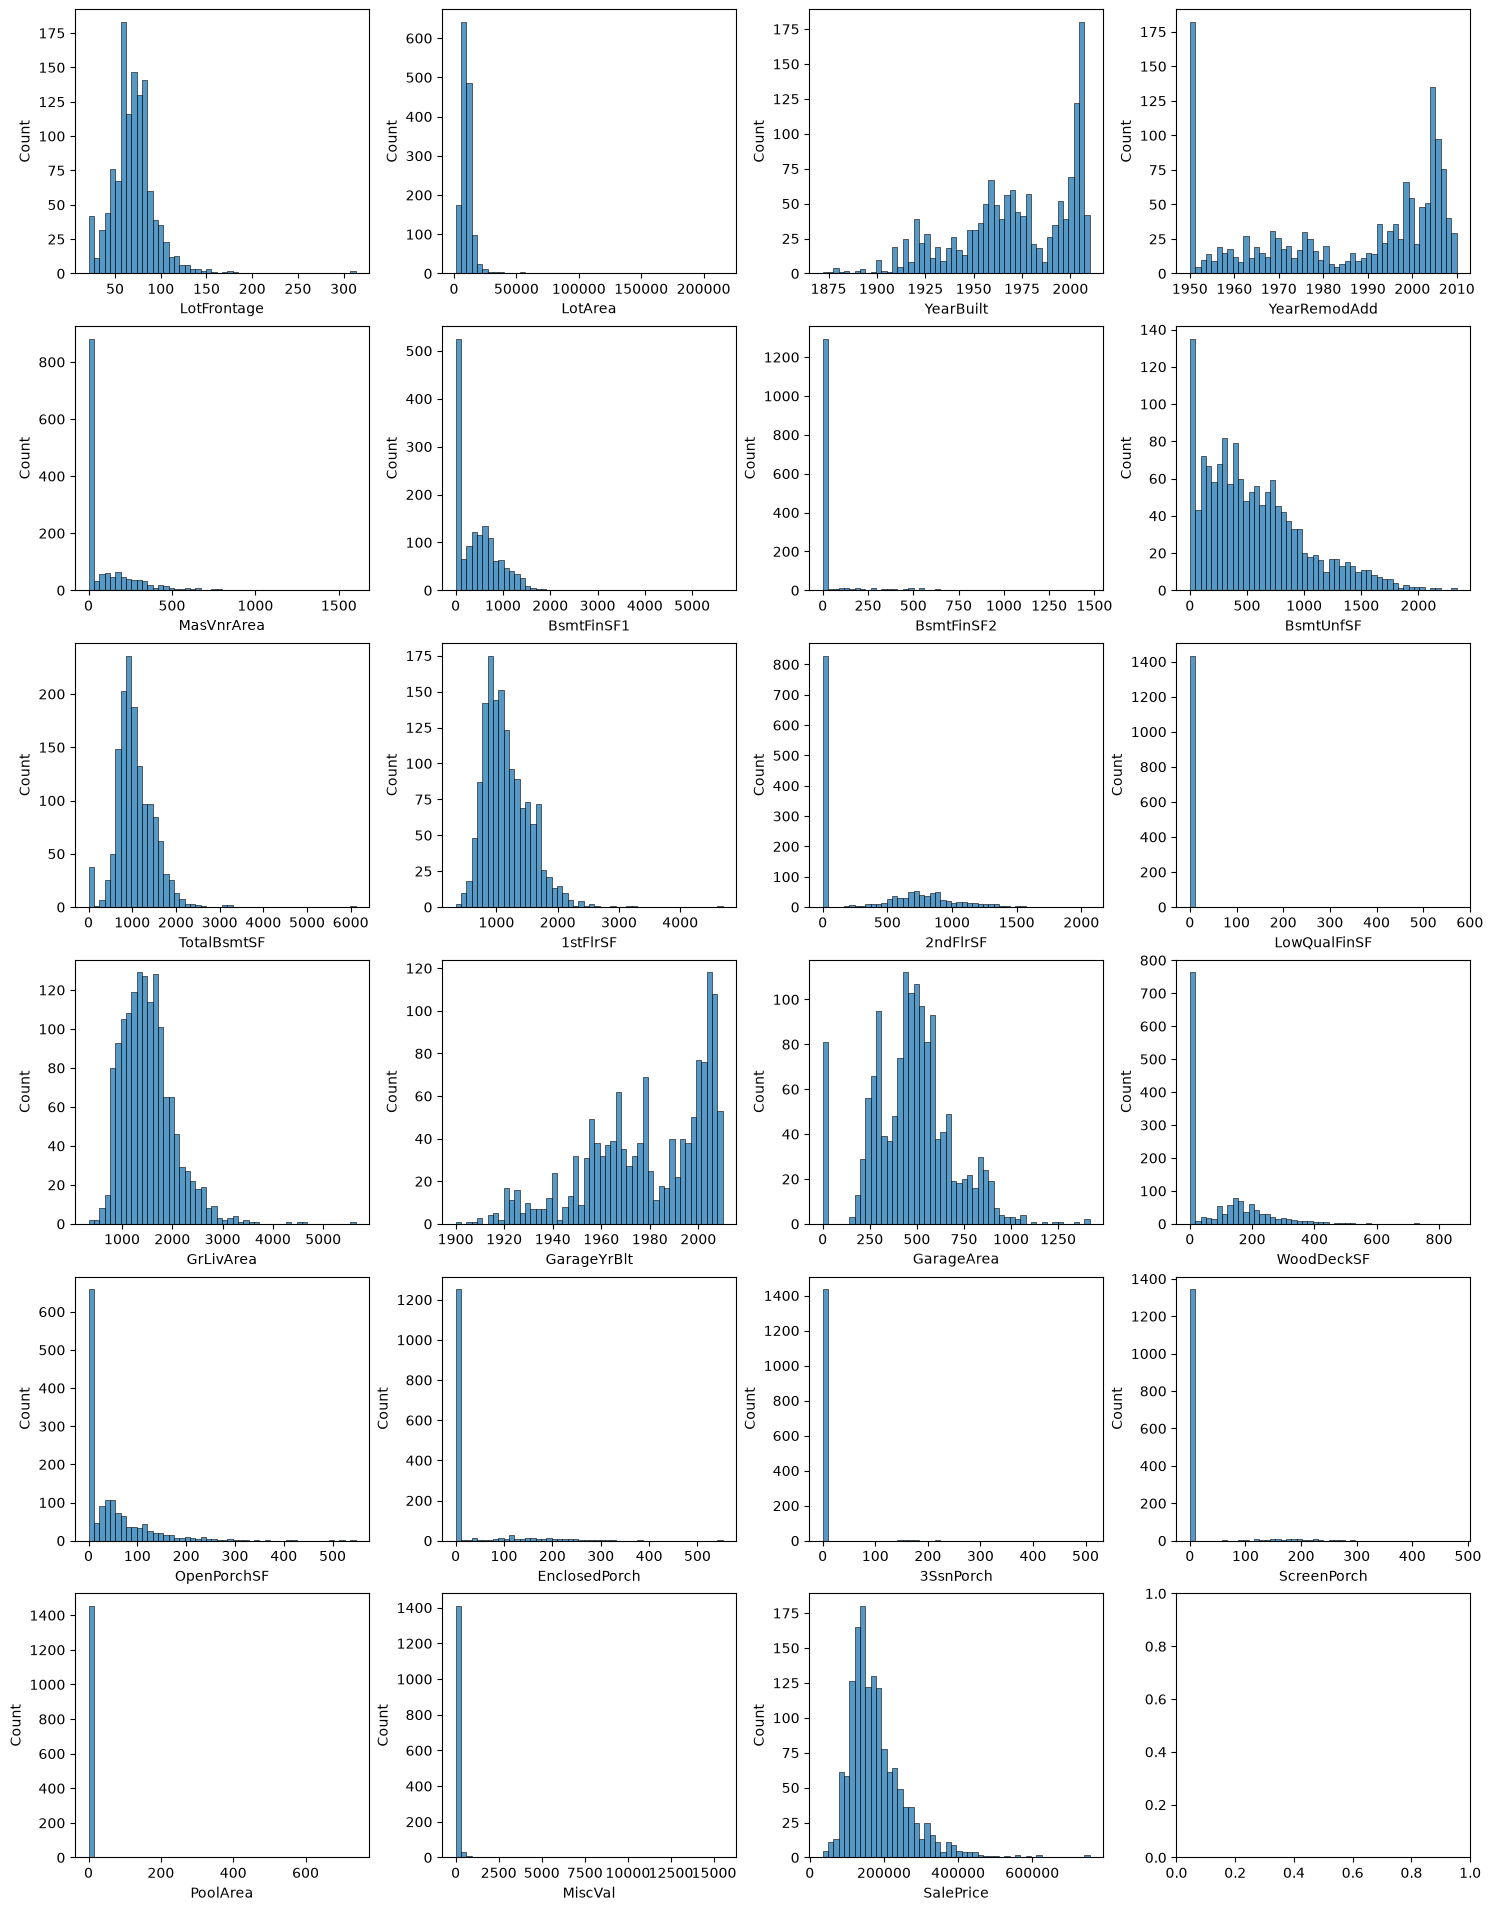

In [11]:
def plot_countplots(df: pd.DataFrame, col_names: list[str]):
    count = len(col_names)
    num_cols = 4
    num_rows = int(np.ceil(count / num_cols))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, num_rows * 4))
    for i, col_name in enumerate(col_names):
        col = i % num_cols
        row = i // num_cols
        sns.histplot(df, ax=axes[row, col], x=col_name, bins=50)
    fig.subplots_adjust(hspace=0.2, wspace=0.25)
    plt.show()

plot_countplots(df, [
    'LotFrontage', 'LotArea',  'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
    'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
    'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'SalePrice'
])

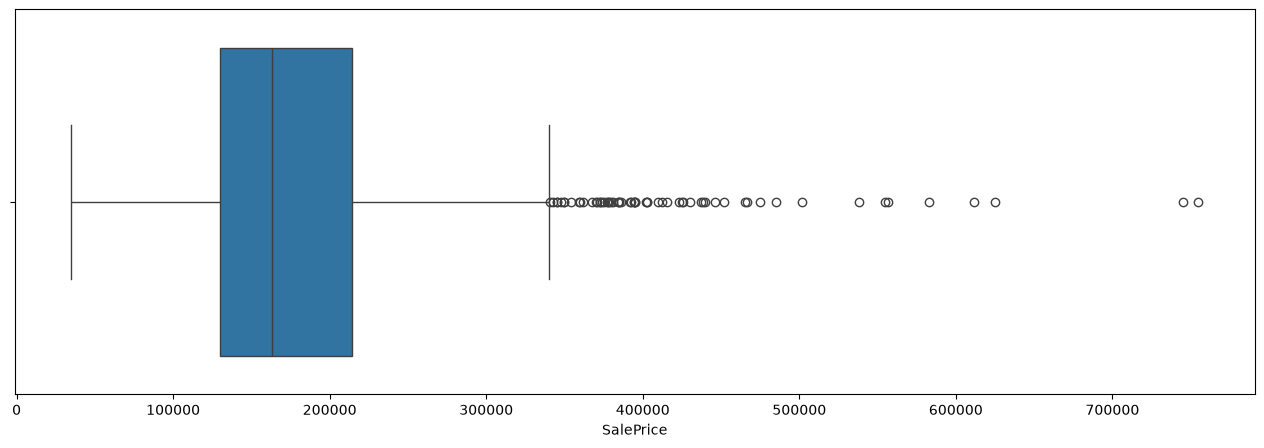

In [12]:
plt.figure(figsize=(16, 5))
sns.boxplot(df, x='SalePrice')
plt.show()

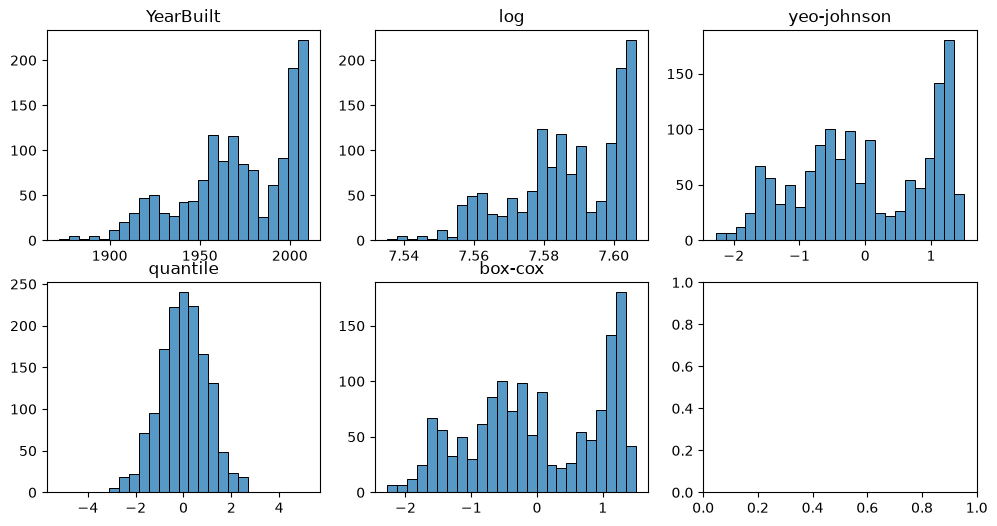

In [13]:
def plot_transforms(df: pd.DataFrame, col_name: str):
    col_s = df[col_name]
    col_d = df[[col_name]]
    has_not_positive = (col_s <= 0).sum() > 0
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))

    ft = FunctionTransformer(np.log1p)
    yj = PowerTransformer(method='yeo-johnson')
    bc = PowerTransformer(method='box-cox')
    qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)

    col_ft = ft.transform(col_s)
    col_yj = yj.fit_transform(col_d)
    col_qt = qt.fit_transform(col_d)
    if not has_not_positive:
        col_bc = bc.fit_transform(col_d)

    sns.histplot(col_s.values, ax=axes[0, 0], bins=25).set_title(col_name)
    sns.histplot(col_ft.values, ax=axes[0, 1], bins=25).set_title('log')
    sns.histplot(col_yj[:, 0], ax=axes[0, 2], bins=25).set_title('yeo-johnson')
    sns.histplot(col_qt[:, 0], ax=axes[1, 0], bins=25).set_title('quantile')
    if not has_not_positive:
        sns.histplot(col_bc[:, 0], ax=axes[1, 1], bins=25).set_title('box-cox')

    for row in axes:
        for ax in row:
            ax.set_ylabel('')
    plt.show()

plot_transforms(df, 'YearBuilt')

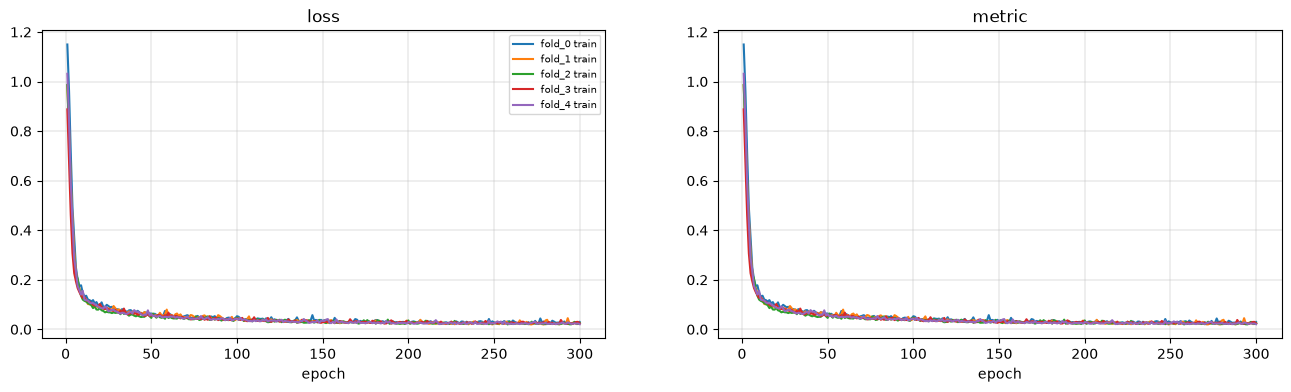

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for path in sorted(glob.glob('checkpoints/scale_target/models/DLM/fold_*/history.csv')):
    h = pd.read_csv(path)
    fold = path.split('\\')[-2]
    if (
        '0' in fold or 
        '1' in fold or 
        '2' in fold or
        '3' in fold or
        '4' in fold or
    False):
        for ax, metric in zip(axes, ['loss', 'metric']):
            line, = ax.plot(h['epoch'], h[f'train_{metric}'], label=f'{fold} train')
            if f'val_{metric}' in h:
                ax.plot(h['epoch'], h[f'val_{metric}'], linestyle='--', color=line.get_color(), label=f'{fold} val')
    
for ax, metric in zip(axes, ['loss', 'metric']):
    ax.set_title(metric); ax.set_xlabel('epoch')
    ax.grid(True, linewidth=0.3)
axes[0].legend(fontsize=7)
plt.show()

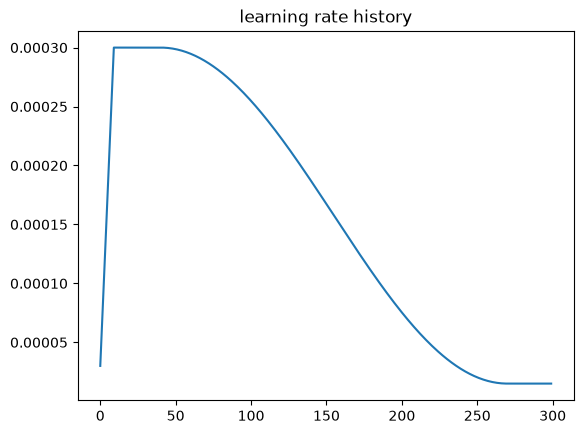

In [15]:
lr = pd.read_csv(r'checkpoints\scale_target\models\DLM\fold_0\history.csv').lr
plt.plot(lr)
plt.title('learning rate history')
plt.show()